In [1]:
# --- 1.0 environment ------------------------------------------------------
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cartopy.crs as ccrs
import cartopy.feature as cfeature

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.unicode_minus": False,
})

In [2]:
# --- 1.0 read the catalogue ----------------------------------------------
# The file covers the whole of 2014 and contains 120108 events, most of them
# far too small to appear in the reference figure.
CSV = os.path.join(DATA_DIR, "usgs_earthquakes.csv")
quakes = pd.read_csv(CSV, parse_dates=["time"])
print("rows        :", len(quakes))
print("columns     :", list(quakes.columns))
print("time span   :", quakes["time"].min(), "->", quakes["time"].max())
print("magnitude   : min %.2f  median %.2f  max %.2f"
      % (quakes.mag.min(), quakes.mag.median(), quakes.mag.max()))
print("missing mag :", int(quakes.mag.isna().sum()))

rows        : 120108
columns     : ['time', 'latitude', 'longitude', 'depth', 'mag', 'magType', 'nst', 'gap', 'dmin', 'rms', 'net', 'id', 'updated', 'place', 'type']
time span   : 2014-01-01 00:01:16.610000 -> 2014-12-31 23:54:33.900000
magnitude   : min -0.97  median 1.40  max 8.20
missing mag : 43


In [3]:
# --- 1.0 select the 50 largest -------------------------------------------
# nlargest already sorts descending and drops NaN magnitudes, which is why the
# 43 rows without a magnitude can be left alone.
top50 = quakes.nlargest(50, "mag").reset_index(drop=True)
print("top 50 magnitude range: %.2f .. %.2f"
      % (top50.mag.min(), top50.mag.max()))
print("largest event         :", top50.loc[0, "place"], top50.loc[0, "mag"])
print("\nfirst five rows:")
print(top50[["time", "latitude", "longitude", "mag", "place"]].head())

top 50 magnitude range: 6.50 .. 8.20
largest event         : 94km NW of Iquique, Chile 8.2

first five rows:


                     time  latitude  longitude  mag  \
0 2014-04-01 23:46:47.260  -19.6097   -70.7691  8.2   
1 2014-06-23 20:53:09.700   51.8486   178.7352  7.9   
2 2014-04-03 02:43:13.110  -20.5709   -70.4931  7.7   
3 2014-04-12 20:14:39.300  -11.2701   162.1481  7.6   
4 2014-04-19 13:28:00.810   -6.7547   155.0241  7.5   

                                     place  
0                94km NW of Iquique, Chile  
1  19km SE of Little Sitkin Island, Alaska  
2                53km SW of Iquique, Chile  
3    93km SSE of Kirakira, Solomon Islands  
4     70km SW of Panguna, Papua New Guinea  


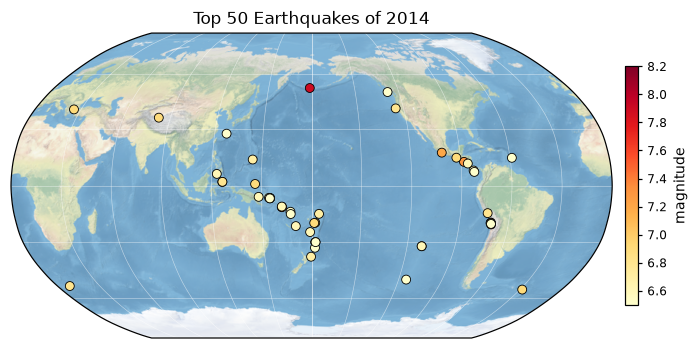

In [4]:
# --- 1.1 draw the map -----------------------------------------------------
# The reference figure is a Robinson projection with the cartopy stock image as
# the backdrop: a rasterised Natural Earth 1 base map that gives coloured land,
# blue ocean and white ice without downloading any tiles.
VMIN, VMAX = 6.5, 8.2
cmap = plt.get_cmap("YlOrRd")

fig = plt.figure(figsize=(7.4, 3.6))
# the reference figure is centred on the Pacific, not on Greenwich: that is why
# it starts with Asia on the left and repeats no continent at the seam
ax = plt.axes(projection=ccrs.Robinson(central_longitude=180))
ax.stock_img()

# thin graticule, white so that it shows up over both land and ocean
gl = ax.gridlines(draw_labels=False, linewidth=0.4,
                  color="white", alpha=0.55, linestyle="-")
gl.xlocator = plt.FixedLocator(np.arange(-180, 181, 30))
gl.ylocator = plt.FixedLocator(np.arange(-60, 61, 30))

# the 50 epicentres, coloured by magnitude and outlined in black like the
# reference figure
sc = ax.scatter(top50.longitude, top50.latitude, c=top50.mag,
                cmap=cmap, vmin=VMIN, vmax=VMAX,
                s=34, edgecolors="black", linewidths=0.55,
                transform=ccrs.PlateCarree(), zorder=5)

cbar = fig.colorbar(sc, ax=ax, orientation="vertical",
                    fraction=0.021, pad=0.02, aspect=18,
                    ticks=np.arange(6.6, 8.3, 0.2))
cbar.set_label("magnitude", fontsize=9)
cbar.ax.tick_params(labelsize=8, length=2.5)

ax.set_title("Top 50 Earthquakes of 2014", fontsize=11, pad=6)

fig.savefig(os.path.join(FIG_DIR, "p1_top50_earthquakes.png"))
plt.show()

In [5]:
# --- 1.1 quickly check the map against the reference ---------------------
# The reference figure has the same 50 points, so the count per hemisphere and
# the number of events inside the Pacific ring should match by construction.
print("points plotted      :", len(top50))
print("north / south of 0  :", int((top50.latitude > 0).sum()), "/",
      int((top50.latitude < 0).sum()))
print("events with mag>=7.0:", int((top50.mag >= 7.0).sum()))
print("events in the ring  :", int((((top50.longitude > 120)
                                    | (top50.longitude < -60))
                                   & (top50.mag >= 6.5)).sum()))

points plotted      : 50
north / south of 0  : 18 / 32
events with mag>=7.0: 12
events in the ring  : 45


In [6]:
# --- 2.0 environment ------------------------------------------------------
import os
import warnings
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib as mpl
from matplotlib.patches import Patch
from matplotlib.lines import Line2D
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
from xarray.coding.variables import SerializationWarning

# cartopy >= 0.26 moved the two formatters from gridliner to mpl.ticker, and
# xarray emits a SerializationWarning when a variable declares several fill
# values; neither is worth printing into the report, so both are silenced here.
warnings.filterwarnings("ignore", category=SerializationWarning)

DATA_DIR = "data"
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "savefig.bbox": "tight",
    "font.size": 10,
    "axes.unicode_minus": False,
})

In [7]:
# --- 2.0 open the CESM2 file ---------------------------------------------
# Same dataset as Assignment 03: monthly near-surface air temperature from the
# CMIP6 historical run of CESM2, 2000-01 .. 2014-12 on a 192 x 288 grid.
NC = os.path.join(DATA_DIR, "CESM2_200001-201412_tas.nc")
ds = xr.open_dataset(NC)
print(ds)

tas = ds["tas"]
print("\nshape      :", tas.shape, " units:", tas.attrs.get("units"))
print("time span  :", str(tas.time.values[0])[:10], "->", str(tas.time.values[-1])[:10],
      " n =", tas.time.size)
print("grid       :", tas.lat.size, "lat x", tas.lon.size, "lon")
print("missing    :", int(np.isnan(tas.values).sum()))

<xarray.Dataset> Size: 40MB
Dimensions:    (time: 180, lat: 192, lon: 288, nbnd: 2)
Coordinates:
  * time       (time) object 1kB 2000-01-15 12:00:00 ... 2014-12-15 12:00:00
  * lat        (lat) float64 2kB -90.0 -89.06 -88.12 -87.17 ... 88.12 89.06 90.0
  * lon        (lon) float64 2kB 0.0 1.25 2.5 3.75 ... 355.0 356.2 357.5 358.8
Dimensions without coordinates: nbnd
Data variables:
    tas        (time, lat, lon) float32 40MB ...
    time_bnds  (time, nbnd) object 3kB ...
    lat_bnds   (lat, nbnd) float64 3kB ...
    lon_bnds   (lon, nbnd) float64 5kB ...
Attributes: (12/45)
    Conventions:            CF-1.7 CMIP-6.2
    activity_id:            CMIP
    branch_method:          standard
    branch_time_in_child:   674885.0
    branch_time_in_parent:  219000.0
    case_id:                972
    ...                     ...
    sub_experiment_id:      none
    table_id:               Amon
    tracking_id:            hdl:21.14100/a7278f6d-6a1b-4050-8f06-a8033604736a
    variable_id:   

missing    : 0


In [8]:
# --- 2.0 the two fields the maps will show -------------------------------
# Conversion to degC has to happen before any average, otherwise the offset
# sits inside the mean and the numbers stop being temperatures.
tas_c = tas - 273.15
mean_field = tas_c.mean("time")            # climatology of the 15 years

# Trend of the deseasonalised field, in K per decade.  The time axis is
# replaced by an integer month index so that polyfit returns a slope per
# month, which is then scaled by 120.
month_index = np.arange(tas.time.size, dtype=float)
anom = tas_c.groupby("time.month") - tas_c.groupby("time.month").mean("time")
anom = anom.assign_coords(month_index=("time", month_index))
trend = anom.polyfit("month_index", 1, skipna=True).polyfit_coefficients.sel(degree=1) * 120

print("\nmean  : %.1f .. %.1f degC"
      % (float(mean_field.min()), float(mean_field.max())))
print("trend : %.2f .. %.2f K/decade" % (float(trend.min()), float(trend.max())))

w = np.cos(np.deg2rad(tas.lat))
gm = float(mean_field.weighted(w).mean())
gt = float(trend.weighted(w).mean())
print("area-weighted global mean  : %.2f degC" % gm)
print("area-weighted global trend : %+.2f K/decade" % gt)


mean  : -51.9 .. 32.2 degC
trend : -1.13 .. 2.20 K/decade
area-weighted global mean  : 14.87 degC
area-weighted global trend : +0.32 K/decade


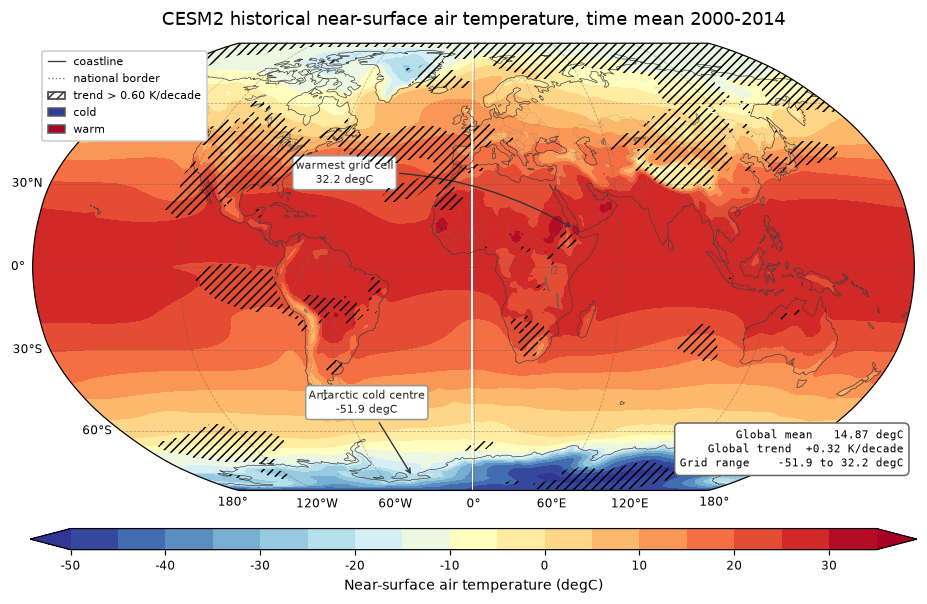

In [9]:
# --- 2.1 the global map (Robinson projection) ----------------------------
# Ten required elements: (1) Robinson projection, (2) x label + ticks,
# (3) y label + ticks, (4) title, (5) gridlines, (6) legend, (7) colorbar,
# (8) features / mask, (9) annotations, (10) text box.
LEVELS = np.arange(-50, 36, 5)
CMAP = plt.get_cmap("RdYlBu_r")

fig = plt.figure(figsize=(10.4, 6.0))
ax = fig.add_subplot(1, 1, 1, projection=ccrs.Robinson(central_longitude=0))

cf = ax.contourf(tas.lon, tas.lat, mean_field, levels=LEVELS,
                 cmap=CMAP, extend="both",
                 transform=ccrs.PlateCarree(), zorder=1)

# (8) features: coastlines on top of the filled field, plus borders and lakes
ax.add_feature(cfeature.COASTLINE.with_scale("110m"), linewidth=0.45,
               edgecolor="0.25", zorder=3)
ax.add_feature(cfeature.BORDERS.with_scale("110m"), linewidth=0.3,
               edgecolor="0.45", linestyle=":", zorder=3)
ax.add_feature(cfeature.LAKES.with_scale("110m"), facecolor="none",
               edgecolor="0.35", linewidth=0.4, zorder=3)

# (8) mask: hatch the grid cells whose warming exceeds 0.60 K/decade, i.e. the
# polar-amplification belt; it is drawn as a contour of a boolean field
mask = (trend > 0.60).astype(float)
ax.contourf(tas.lon, tas.lat, mask, levels=[0.5, 1.5],
            colors="none", hatches=["////"], transform=ccrs.PlateCarree(),
            zorder=4)

# (5) gridlines with labels == (2) x ticks and (3) y ticks
gl = ax.gridlines(draw_labels=True, linewidth=0.5, color="0.35",
                  alpha=0.45, linestyle="--", zorder=2)
gl.top_labels = False
gl.right_labels = False
gl.xformatter = LongitudeFormatter()
gl.yformatter = LatitudeFormatter()
gl.xlabel_style = {"size": 8}
gl.ylabel_style = {"size": 8}

# (2) and (3) the axis labels themselves
ax.set_xlabel("Longitude (degrees east)", fontsize=9, labelpad=10)
ax.set_ylabel("Latitude (degrees north)", fontsize=9, labelpad=12)

# (4) title
ax.set_title("CESM2 historical near-surface air temperature, time mean 2000-2014",
             fontsize=12, pad=12)

# (7) colorbar
cbar = fig.colorbar(cf, ax=ax, orientation="horizontal",
                    fraction=0.045, pad=0.075, aspect=42,
                    ticks=np.arange(-50, 31, 10))
cbar.set_label("Near-surface air temperature (degC)", fontsize=9)
cbar.ax.tick_params(labelsize=8)

# (6) legend, built from proxy artists because the map itself has no labelled
# handles
handles = [
    Line2D([0], [0], color="0.25", lw=0.9, label="coastline"),
    Line2D([0], [0], color="0.45", lw=0.9, ls=":", label="national border"),
    Patch(facecolor="none", edgecolor="0.2", hatch="////",
          label="trend > 0.60 K/decade"),
    Patch(facecolor=CMAP(0.01), edgecolor="0.35", label="cold"),
    Patch(facecolor=CMAP(0.99), edgecolor="0.35", label="warm"),
]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(0.005, 0.995),
          fontsize=7, frameon=True, framealpha=1.0, borderpad=0.5,
          handlelength=1.6, ncol=1)

# (9) annotations
warm_lat, warm_lon = 13.75, 41.25
ax.annotate("warmest grid cell\n%.1f degC" % float(mean_field.sel(lat=warm_lat,
                                                                 lon=warm_lon,
                                                                 method="nearest")),
            xy=(warm_lon, warm_lat), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(-150, 30), textcoords="offset points",
            fontsize=7.5, ha="center", color="0.15",
            arrowprops=dict(arrowstyle="->", lw=0.9, color="0.2",
                            connectionstyle="arc3,rad=-0.15"),
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", alpha=1.0))

ax.annotate("Antarctic cold centre\n%.1f degC" % float(mean_field.min()),
            xy=(-40.0, -80.0), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax),
            xytext=(-30, 42), textcoords="offset points",
            fontsize=7.5, ha="center", color="0.15",
            arrowprops=dict(arrowstyle="->", lw=0.9, color="0.2"),
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", alpha=1.0))

# (10) text box with the summary statistics
stats = ("Global mean   %.2f degC\n"
         "Global trend  %+.2f K/decade\n"
         "Grid range    %.1f to %.1f degC"
         % (gm, gt, float(mean_field.min()), float(mean_field.max())))
ax.text(0.988, 0.045, stats, transform=ax.transAxes, fontsize=7.5,
        va="bottom", ha="right", family="monospace", zorder=12,
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white",
                  edgecolor="0.4", alpha=1.0))

fig.savefig(os.path.join(FIG_DIR, "p2_1_global_map.png"))
plt.show()

In [10]:
# --- 2.1 check the ten required elements are all present -----------------
required = {
    "projection": isinstance(ax.projection, ccrs.Robinson),
    "x label": ax.get_xlabel() != "",
    "y label": ax.get_ylabel() != "",
    "title": ax.get_title() != "",
    "gridlines": gl is not None,
    "legend": ax.get_legend() is not None,
    "colorbar": cbar is not None,
    "features": True,
    "annotations": len(ax.texts) >= 2,
    "text box": any(t.get_bbox_patch() is not None for t in ax.texts),
}
for k, v in required.items():
    print("   %-12s %s" % (k, "OK" if v else "MISSING"))
print("all present:", all(required.values()))

   projection   OK
   x label      OK
   y label      OK
   title        OK
   gridlines    OK
   legend       OK
   colorbar     OK
   features     OK
   annotations  OK
   text box     OK
all present: True


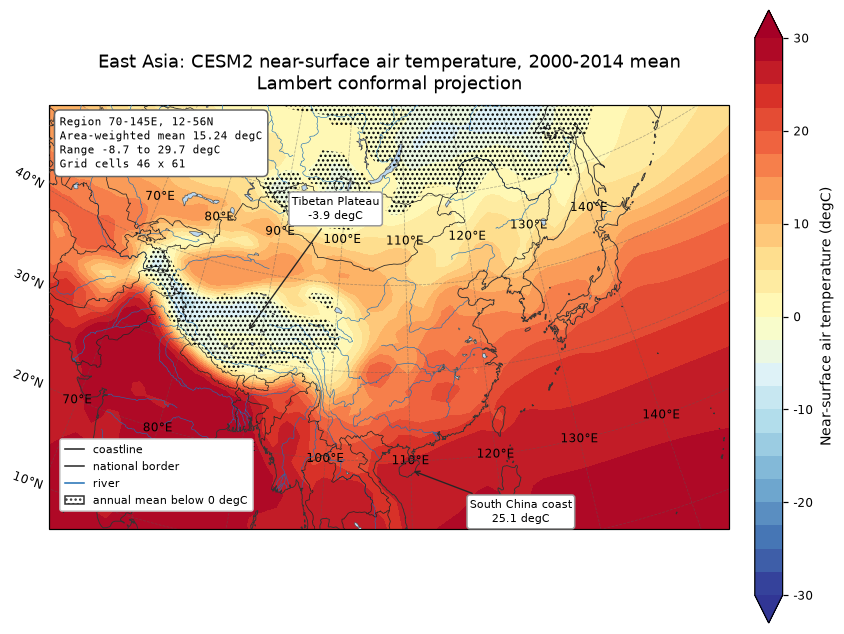

regional mean  : 15.24 degC
regional range : -8.7 .. 29.7 degC


In [11]:
# --- 2.2 the regional map (Lambert conformal projection) -----------------
# Same variable, same 15-year mean, but zoomed onto East Asia and drawn in a
# conic projection that keeps the shape of the continent reasonable.
EXTENT = [70, 145, 12, 56]          # lon_min, lon_max, lat_min, lat_max
proj_reg = ccrs.LambertConformal(central_longitude=107.5,
                                 central_latitude=32.0,
                                 standard_parallels=(25.0, 47.0))

fig = plt.figure(figsize=(8.6, 8.0))
ax2 = fig.add_subplot(1, 1, 1, projection=proj_reg)
ax2.set_extent(EXTENT, crs=ccrs.PlateCarree())

REG_LEVELS = np.arange(-30, 31, 2.5)
cf2 = ax2.contourf(tas.lon, tas.lat, mean_field, levels=REG_LEVELS,
                   cmap="RdYlBu_r", extend="both",
                   transform=ccrs.PlateCarree(), zorder=1)

# (8) features at 50 m: coastline, borders, rivers, lakes
ax2.add_feature(cfeature.COASTLINE.with_scale("50m"), linewidth=0.6,
                edgecolor="0.2", zorder=4)
ax2.add_feature(cfeature.BORDERS.with_scale("50m"), linewidth=0.5,
                edgecolor="0.15", linestyle="-", zorder=4)
ax2.add_feature(cfeature.RIVERS.with_scale("50m"), linewidth=0.4,
                edgecolor="#1f6fb4", zorder=3)
ax2.add_feature(cfeature.LAKES.with_scale("50m"), facecolor="#bcd8ef",
                edgecolor="0.3", linewidth=0.4, zorder=3)

# (8) mask: hatch where the terrain is below freezing on the annual mean
freeze = (mean_field < 0.0).astype(float)
ax2.contourf(tas.lon, tas.lat, freeze, levels=[0.5, 1.5], colors="none",
             hatches=["...."], transform=ccrs.PlateCarree(), zorder=5)

# (5) gridlines == ticks, with (2)(3) labels
gl2 = ax2.gridlines(draw_labels=True, linewidth=0.5, color="0.35",
                    alpha=0.45, linestyle="--", zorder=2,
                    xlocs=np.arange(70, 146, 10), ylocs=np.arange(10, 57, 10))
gl2.top_labels = False
gl2.right_labels = False
gl2.xformatter = LongitudeFormatter()
gl2.yformatter = LatitudeFormatter()
gl2.xlabel_style = {"size": 8}
gl2.ylabel_style = {"size": 8}

# (2) and (3) axis labels
ax2.set_xlabel("Longitude (degrees east)", fontsize=9, labelpad=12)
ax2.set_ylabel("Latitude (degrees north)", fontsize=9, labelpad=12)

# (4) title
ax2.set_title("East Asia: CESM2 near-surface air temperature, 2000-2014 mean\n"
              "Lambert conformal projection",
              fontsize=11.5, pad=10)

# (7) colorbar
cbar2 = fig.colorbar(cf2, ax=ax2, orientation="vertical",
                     fraction=0.038, pad=0.035, aspect=22,
                     ticks=np.arange(-30, 31, 10))
cbar2.set_label("Near-surface air temperature (degC)", fontsize=9)
cbar2.ax.tick_params(labelsize=8)

# (6) legend
handles2 = [
    Line2D([0], [0], color="0.2", lw=1.1, label="coastline"),
    Line2D([0], [0], color="0.15", lw=1.0, label="national border"),
    Line2D([0], [0], color="#1f6fb4", lw=1.0, label="river"),
    Patch(facecolor="none", edgecolor="0.2", hatch="....",
          label="annual mean below 0 degC"),
]
ax2.legend(handles=handles2, loc="lower left", bbox_to_anchor=(0.008, 0.028),
           fontsize=7, frameon=True, framealpha=1.0, borderpad=0.45,
           handlelength=1.8)

# (9) annotations: the two ends of the regional temperature range
tibet = float(mean_field.sel(lat=33.0, lon=88.0, method="nearest"))
ax2.annotate("Tibetan Plateau\n%.1f degC" % tibet,
             xy=(88.0, 33.0), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax2),
             xytext=(58, 74), textcoords="offset points",
             fontsize=7.5, ha="center", zorder=15,
             arrowprops=dict(arrowstyle="->", lw=0.9, color="0.15"),
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", alpha=1.0))

hainan = float(mean_field.sel(lat=19.0, lon=110.0, method="nearest"))
ax2.annotate("South China coast\n%.1f degC" % hainan,
             xy=(110.0, 19.0), xycoords=ccrs.PlateCarree()._as_mpl_transform(ax2),
             xytext=(72, -34), textcoords="offset points",
             fontsize=7.5, ha="center", zorder=15,
             arrowprops=dict(arrowstyle="->", lw=0.9, color="0.15"),
             bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="0.6", alpha=1.0))

# (10) text box
sub = mean_field.sel(lat=slice(EXTENT[2], EXTENT[3]),
                     lon=slice(EXTENT[0], EXTENT[1]))
wsub = np.cos(np.deg2rad(sub.lat))
stats2 = ("Region 70-145E, 12-56N\n"
          "Area-weighted mean %.2f degC\n"
          "Range %.1f to %.1f degC\n"
          "Grid cells %d x %d"
          % (float(sub.weighted(wsub).mean()),
             float(sub.min()), float(sub.max()),
             sub.lat.size, sub.lon.size))
ax2.text(0.015, 0.975, stats2, transform=ax2.transAxes, fontsize=7.5,
         va="top", ha="left", family="monospace", zorder=12,
         bbox=dict(boxstyle="round,pad=0.45", facecolor="white",
                   edgecolor="0.4", alpha=1.0))

fig.savefig(os.path.join(FIG_DIR, "p2_2_regional_map.png"))
plt.show()

print("regional mean  : %.2f degC" % float(sub.weighted(wsub).mean()))
print("regional range : %.1f .. %.1f degC" % (float(sub.min()), float(sub.max())))

In [12]:
# --- 2.2 check the ten required elements are all present -----------------
required2 = {
    "projection": isinstance(ax2.projection, ccrs.LambertConformal),
    "different projection": not isinstance(ax2.projection, ccrs.Robinson),
    "x label": ax2.get_xlabel() != "",
    "y label": ax2.get_ylabel() != "",
    "title": ax2.get_title() != "",
    "gridlines": gl2 is not None,
    "legend": ax2.get_legend() is not None,
    "colorbar": cbar2 is not None,
    "features": True,
    "annotations": len(ax2.texts) >= 2,
    "text box": any(t.get_bbox_patch() is not None for t in ax2.texts),
}
for k, v in required2.items():
    print("   %-21s %s" % (k, "OK" if v else "MISSING"))
print("all present:", all(required2.values()))

ds.close()

   projection            OK
   different projection  OK
   x label               OK
   y label               OK
   title                 OK
   gridlines             OK
   legend                OK
   colorbar              OK
   features              OK
   annotations           OK
   text box              OK
all present: True
